### **REGRESSION PROBLEM**

In [40]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR



In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
path = r"/content/drive/MyDrive/Datasets/modified_data.csv"
df = pd.read_csv(path)
print(type(df))

<class 'pandas.core.frame.DataFrame'>


## **Check dataset**

In [43]:
print("\nMissing Values:")
print(df.isnull().sum())
print(df.duplicated().sum())


Missing Values:
date              0
price             0
bedrooms          0
bathrooms         0
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
street            0
city              0
statezip          0
price_per_sqft    0
dtype: int64
0


In [44]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   object 
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   float64
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   object 
 15  city            4600 non-null   object 
 16  statezip        4600 non-null   object 
 17  price_per_sqft  4600 non-null   f

### **Remove unnecessary columns**

In [45]:
df_model = df.drop(
    ["price", "price_per_sqft", "street", "date"],
    axis=1
)

print(df_model.head())

   bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  view  \
0       3.0       1.50         1340      7912     1.5           0     0   
1       5.0       2.50         3650      9050     2.0           0     4   
2       3.0       2.00         1930     11947     1.0           0     0   
3       3.0       2.25         2000      8030     1.0           0     0   
4       4.0       2.50         1940     10500     1.0           0     0   

   condition  sqft_above  sqft_basement  yr_built  yr_renovated       city  \
0          3        1340              0      1955          2005  Shoreline   
1          5        3370            280      1921             0    Seattle   
2          4        1930              0      1966             0       Kent   
3          4        1000           1000      1963             0   Bellevue   
4          4        1140            800      1976          1992    Redmond   

   statezip  
0  WA 98133  
1  WA 98119  
2  WA 98042  
3  WA 98008  
4  WA 9805

**Separate X and y**

In [46]:
X = df_model
y = df["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4600, 14)
y shape: (4600,)


one-hot encoding

In [47]:
X = pd.get_dummies(
    X,
    columns=["city", "statezip"],
    drop_first=True
)

print("New X shape:", X.shape)

New X shape: (4600, 131)


## **Train-Test Split**

In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (3680, 131)
Testing: (920, 131)


### **Feature Scaling**

In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [50]:
def evaluate_model(model_name, y_test, y_pred):

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)
    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("R²  :", r2)

    return mae, mse, rmse, r2

## **Linear Regression**

In [51]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_scaled, y_train)



LinearRegression()

In [52]:
y_pred_lr = lr.predict(X_test_scaled)

In [53]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R²:", r2_lr)

Linear Regression
MAE: 155810.17659393224
MSE: 963771887403.9572
RMSE: 981718.8433578919
R²: 0.054983236665073876


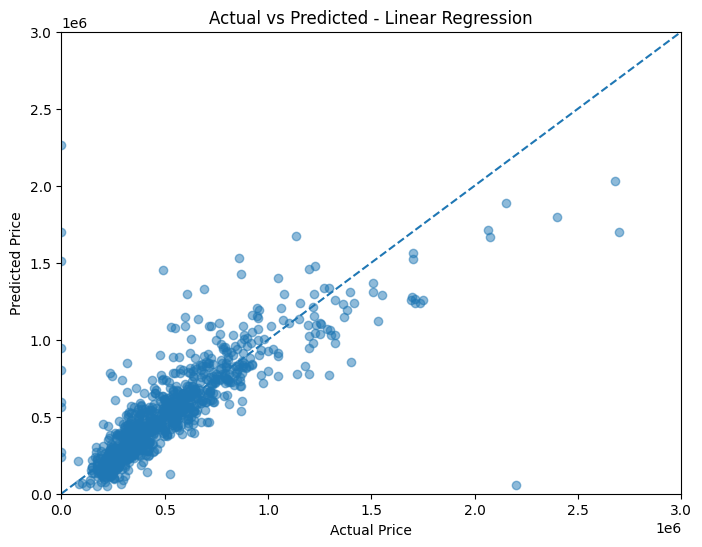

In [54]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.5
)

plt.plot(
    [0, 3000000],
    [0, 3000000],
    linestyle="--"
)

plt.xlim(0, 3000000)
plt.ylim(0, 3000000)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

## **Polynomial Regression**

In [55]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)

In [56]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_lr = LinearRegression()

poly_lr.fit(
    X_train_poly,
    y_train
)



LinearRegression()

In [57]:
y_pred_poly = poly_lr.predict(X_test_poly)

In [58]:


mae_poly, mse_poly, rmse_poly, r2_poly = evaluate_model(
    "Polynomial Regression",
    y_test,
    y_pred_poly
)


Polynomial Regression
MAE : 182711.5422787975
MSE : 1045302143199.496
RMSE: 1022400.1874019273
R²  : -0.024960429935646067


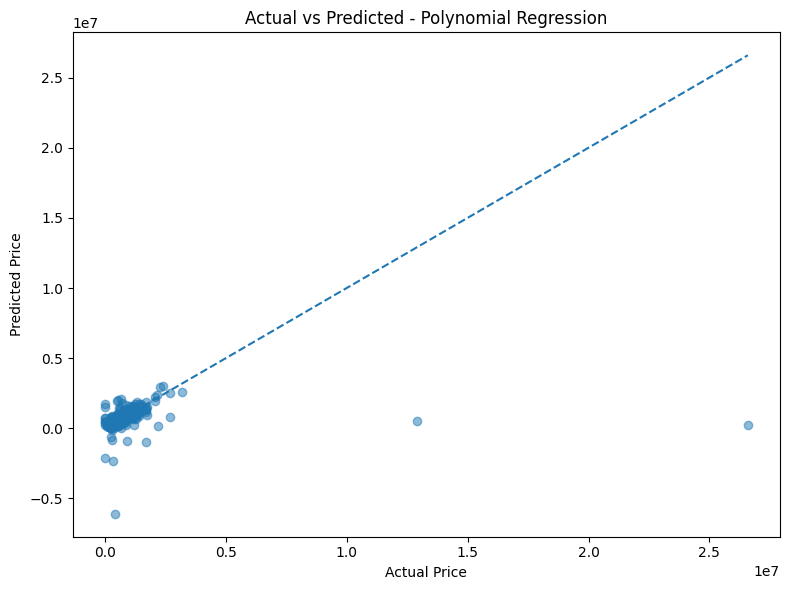

In [59]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_poly,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Polynomial Regression")

plt.tight_layout()
plt.show()

### **Decision Tree Regression**

In [60]:
dt = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt.fit(
    X_train,
    y_train
)



DecisionTreeRegressor(max_depth=10, random_state=42)

In [61]:
y_pred_dt = dt.predict(X_test)

In [62]:
mae_dt, mse_dt, rmse_dt, r2_dt = evaluate_model(
    "Decision Tree Regression",
    y_test,
    y_pred_dt
)


Decision Tree Regression
MAE : 193518.32563895016
MSE : 995873735607.3317
RMSE: 997934.7351442035
R²  : 0.02350609452935748


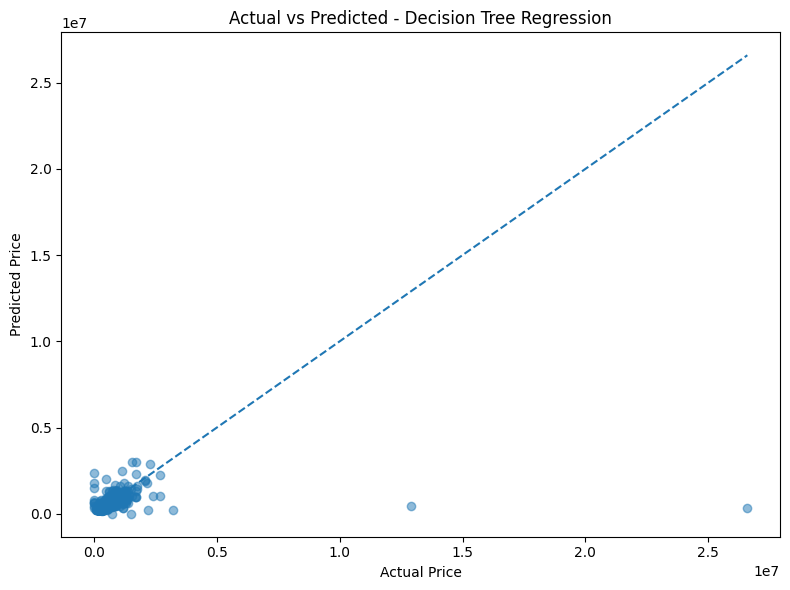

In [63]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_dt,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Decision Tree Regression")

plt.tight_layout()
plt.show()

### **Random Forest Regression**

In [64]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train,
    y_train
)



RandomForestRegressor(n_jobs=-1, random_state=42)

In [65]:
y_pred_rf = rf.predict(X_test)

In [66]:
mae_rf, mse_rf, rmse_rf, r2_rf = evaluate_model(
    "Random Forest Regression",
    y_test,
    y_pred_rf
)


Random Forest Regression
MAE : 157372.72232739133
MSE : 971791643362.2466
RMSE: 985794.9296695772
R²  : 0.04711954618240888


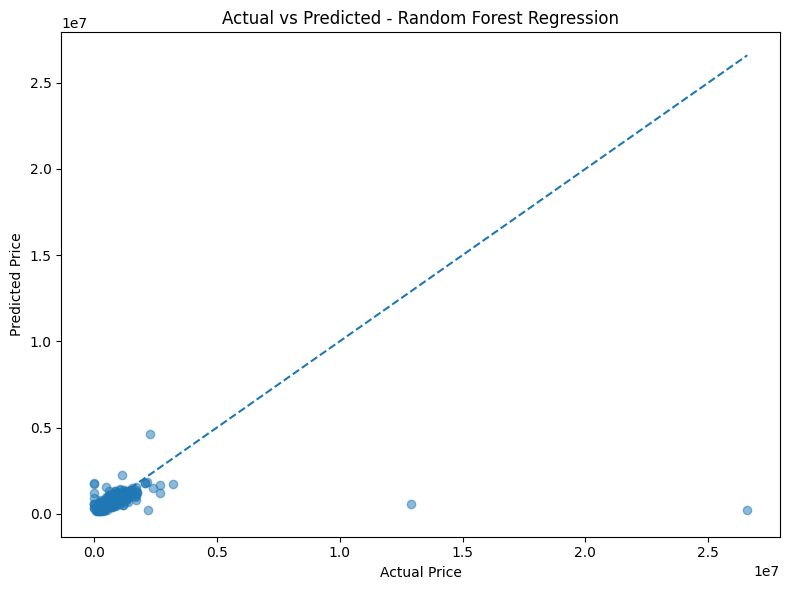

In [67]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Random Forest Regression")

plt.tight_layout()
plt.show()

## **KNN Regression**

In [68]:
knn = KNeighborsRegressor(
    n_neighbors=5
)

knn.fit(
    X_train_scaled,
    y_train
)



KNeighborsRegressor()

In [69]:
y_pred_knn = knn.predict(X_test_scaled)

In [70]:
mae_knn, mse_knn, rmse_knn, r2_knn = evaluate_model(
    "KNN Regression",
    y_test,
    y_pred_knn
)


KNN Regression
MAE : 156170.6989543478
MSE : 967146039450.8835
RMSE: 983435.833926588
R²  : 0.051674746048092746


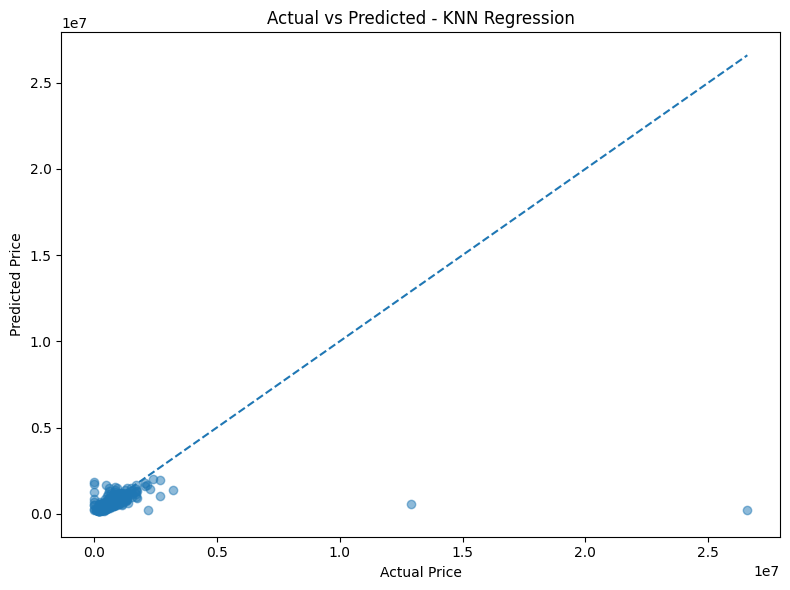

In [71]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_knn,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - KNN Regression")

plt.tight_layout()
plt.show()

**Support Vector Regression**

In [72]:
svr = SVR(
    kernel="rbf"
)

svr.fit(
    X_train_scaled,
    y_train
)



SVR()

In [73]:
y_pred_svr = svr.predict(X_test_scaled)

In [74]:
mae_svr, mse_svr, rmse_svr, r2_svr = evaluate_model(
    "Support Vector Regression",
    y_test,
    y_pred_svr
)


Support Vector Regression
MAE : 267385.6101905014
MSE : 1033502242677.3406
RMSE: 1016613.1234040512
R²  : -0.013390156985313206


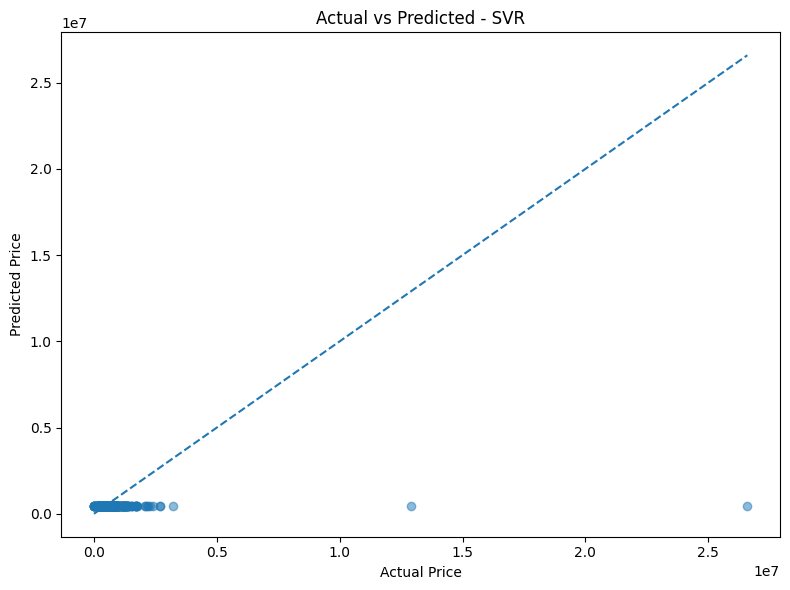

In [75]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_svr,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - SVR")

plt.tight_layout()
plt.show()